<a href="https://colab.research.google.com/github/etorrey-vc/CMPU-250/blob/main/Torrey_Assignment_4_%7C_CMPU_250.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<abbr>CMPU</abbr>&thinsp;250 · Assignment 4

In [100]:
# @title run this first
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

!pip install fairlearn
import fairlearn

from fairlearn.reductions import ExponentiatedGradient, FalsePositiveRateParity
from fairlearn.metrics import MetricFrame, selection_rate, false_positive_rate, false_negative_rate

!pip install aif360
import aif360

# suppress warnings
pd.options.mode.chained_assignment = None
pd.options.mode.copy_on_write = True

&nbsp;

# Exercise 1: Gradient Descent for Logistic Regression (35 points)

The code below creates and plots synthetic data. We'll use this data in Exercise 1:

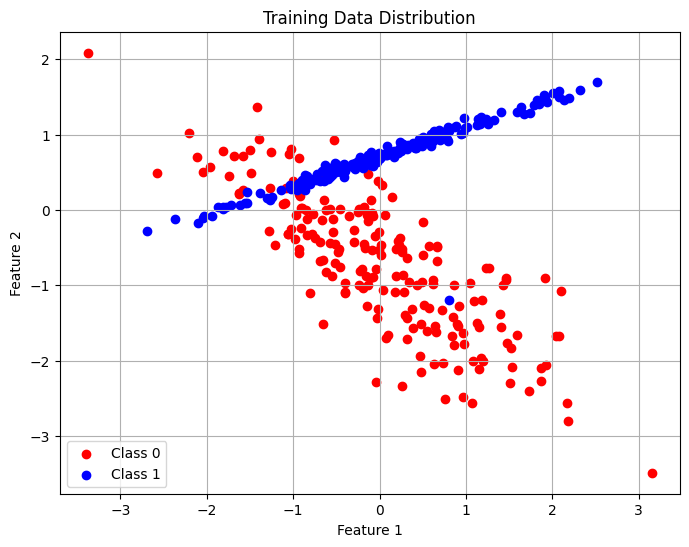

In [101]:
# binary classification dataset
X, y = make_classification(n_samples=500, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, random_state=42)
y = y.reshape(-1, 1)  # make y a column vector

# split and scale data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


def plot_data(X, y, title="Synthetic Binary Classification Data"):
    plt.figure(figsize=(8, 6))
    plt.scatter(X[y[:, 0] == 0][:, 0], X[y[:, 0] == 0][:, 1], color='red', label='Class 0')
    plt.scatter(X[y[:, 0] == 1][:, 0], X[y[:, 0] == 1][:, 1], color='blue', label='Class 1')
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.grid(True)
    plt.show()

# plot train set
plot_data(X_train, y_train, title="Training Data Distribution")

&nbsp;

### Review: Logistic model



A logistic model (for binary classification) outputs the predicted probability $y_{prob}\,$ that a binary target variable $y \in \{0, 1\}$ equals 1 given the $d$-dimensional feature vector for a single sample $\mathbf{x} = (x_1, x_2, \dots, x_d)$, based on the following equation:

$$y_{prob} = \text{logistic}\left(\mathbf{\theta_1}^\top \mathbf{x} + \theta_0 \right)$$

where we choose some $d$-dimensional vector of weights $\mathbf{\theta_1}$ and bias (intercept) term $\theta_0$, and the logistic function is defined as:

$$\text{logistic}(z) = \frac{1}{1 + e^{-z}}$$


(Remember that we can turn the output of a logistic model into binary classification --0 or 1-- by thresholding it at .5, i.e., seeing if the probability that the class 1 is is greater than 50%. But, we won't do that yet.)

The code for this logistic model is below:

In [102]:
def logistic(z):
    return 1 / (1 + np.exp(-z))

def log_prob(theta_1 : np.array, theta_0 : float, x : np.array) -> float:
  '''Returns the output of the logistic model (probability)
  for input weights w and bias term b on a single sample x'''

  return theta_1.dot(x) + theta_0

For example, if all the model parameters were set to 1, then the predicted probability for the first sample of `X_train` would be:

In [103]:
theta_1 = np.ones(X_train[0].shape)
theta_0 = 1
x = X_train[0]

log_prob(theta_1, theta_0, x)

np.float64(1.1783731593048987)

&nbsp;

## Q1 (5 points)

So far in class, we've evaluated logistic regression models by how accurate their binary predictions are (otherwise known as *0-1 loss*).

But, in practice, it's actually standard to use a different type of loss function, called **cross-entropy loss** when training a logistic regression model. Intuitively, cross-entropy loss measures the difference between two probability distributions (the predicted probabilities and the true probabilities).

---

**Task:** Look at the plot of the data above. Make an educated guess at what you think are good model parameters (weights and bias term) for a logistic model. (Don't think about your guess too much -- it doesn't have to be perfect, just choose something.)

Then, use the `binary_cross_entropy_loss` function defined below to output the loss of your model over the train set. In other words, use your (guessed) parameters in the `log_prob` function above to make predictions `y_pred` for all samples in `X_train`. Then, use your predicted probabilities `y_pred` and the true probabilities `y_train` to calculate the binary cross-entropy loss of your guessed model over the train set.

Use binary cross-entropy loss as your loss function, defined by the following equation:

$$L = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log\left(y_{prob}^{(i)}\right) + \left(1 - y^{(i)}\right) \log\left(1 - y_{prob}^{(i)}\right) \right]$$

where $m$ is the sample size, the superscript $(i)$ denotes the $i$-th sample (not an exponent), and the predicted value $y_{prob} = \text{logistic}\left(\mathbf{\theta_1}^\top \mathbf{x}^{(i)} + \theta_0 \right)$ --- for 2-dimensional vectors $\mathbf{x}^{(i)}$ and $\mathbf{\theta_1}$ of features and model weights, respectively.

*Hint: You may want to define a Python function that takes in two vectors `y` and `y_pred` and returns the binary cross-entropy loss.*

---

In [104]:
def binary_cross_entropy_loss(y_true : np.array, y_prob : np.array) -> float:
  '''Returns cross entropy loss between arrays y_true and y_prob, both of size m'''

  eps = 1e-15 # tiny value to correct for numerical errors
  m = y_true.shape[0] # sample size

  loss = - np.mean(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob + eps))

  return loss

In [105]:
# model param guess + prediction
my_theta_1 = np.array([0.3,-1.0])
my_theta_0 = 1.0

y_pred = logistic(X_train @ my_theta_1 + my_theta_0).reshape(-1, 1)


# check that shapes match
print(y_pred.shape, "and", y_train.shape)

# loss
binary_cross_entropy_loss(y_train, y_pred)


binary_cross_entropy_loss(y_train, y_pred)

(400, 1) and (400, 1)


np.float64(1.2580017356681272)

*Hint: Double-check that your `y_prob` and `y_train` are the same shape. You may end up with `y_prob` being shape (400,). If that's the case, you may have to use `.reshape()` to make sure that the shapes of `y_prob` and `y_train` are the same before you pass them into the `binary_cross_entropy_loss` function.*

*Hint 2: If you set all your model parameters to 1 ---i.e., $\mathbf{\theta_1} = (1,1)$ and $\theta_0 = 1$,--- then you should get loss of about 0.584.*

&nbsp;

## Q2 (25 points)

Write a function `logistic_regression_gradient_descent` to train a logistic regression model using gradient descent. Your function should take in a feature set, a ground truth label set (of binary labels), a learning rate (step size), and a max number of epochs. Then, it should return optimal parameters for a logistic model (found using gradient descent), as well as a list containing the loss for every epoch.

Specifically, in your function, you should first initialize model parameters $\mathbf{\theta_1}$ and $\theta_0$. Then, in each epoch, you should implement the following steps:
1. Compute predicted probabilities $y_{prob}$ based on `X_train` (defined above) using a logistic model with the current model parameters (either the initial parameters or the parameters from step 4 of the last epoch)
2. Compute the loss over `y_train`
3. Compute the gradients for $\mathbf{\theta_1}$ and $\theta_0$ based on the following equations (gradients of the binary cross-entropy loss function specified above):

$$\frac{\partial L}{\partial \theta_1} = \frac{1}{m} \sum_{i=1}^{m} \left( y_{prob}^{(i)} - y^{(i)} \right) \mathbf{x}^{(i)}$$

$$\frac{\partial L}{\partial \theta_0} = \frac{1}{m} \sum_{i=1}^{m} \left( y_{prob}^{(i)} - y^{(i)} \right)$$

where $m$ is the sample size, the superscript $(i)$ denotes the $i$-th sample, and the predicted value $y_{prob} = \text{logistic}\left(\mathbf{\theta_1}^\top \mathbf{x}^{(i)} + \theta_0 \right)$ for 2-dimensional vectors of features $\mathbf{x}$ and model weights $\mathbf{\theta_1}$.

4. Update your parameters $\mathbf{\theta_1}$ and $\theta_0$ using gradient descent
5. Append the loss to a list
6. Every 50 epochs, print the loss that epoch.

After you hit the max epochs, stop this process.

Use the code provided at the end of the code block below to call your function and plot the loss per epoch.

In [106]:
# gradient descent for logistic regression
def logistic_regression_gradient_descent(X, y, learning_rate, epochs):
    X = np.array(X)
    y = np.array(y).ravel()

    m, n_features = X.shape

    theta1 = np.zeros(n_features)
    theta0 = 0.0

    losses = []
    eps = 1e-12

    for epoch in range(epochs):
        z = X @ theta1 + theta0
        y_prob = logistic(z)

        loss = -np.mean(y * np.log(y_prob + eps) + (1 - y) * np.log(1 - y_prob + eps))

        error = y_prob - y
        grad_theta1 = (X.T @ error) / m
        grad_theta0 = np.sum(error) / m

        # update thetas
        theta1 -= learning_rate * grad_theta1
        theta0 -= learning_rate * grad_theta0

        # append loss
        losses.append(loss)

        # every 50 epochs
        if epoch % 50 == 0:
            print(f"Epoch {epoch}: loss = {loss:.4f}")

    return theta1, theta0, losses

Epoch 0: loss = 0.6931
Epoch 50: loss = 0.6374
[0.00818686 0.31454575] 0.004322196168460702


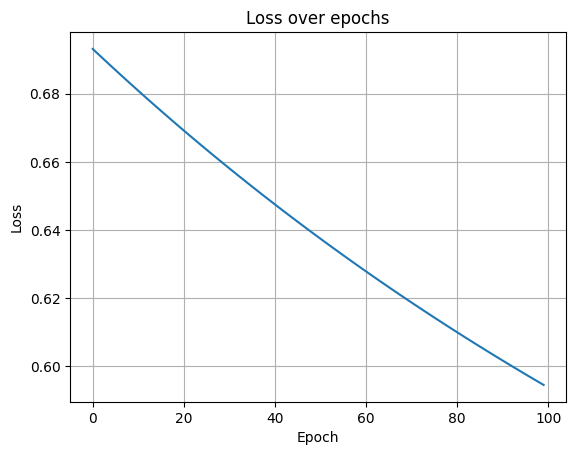

In [107]:
# train the model
weights_trained, intercept_trained, losses = logistic_regression_gradient_descent(X_train, y_train, learning_rate=0.01, epochs=100)

print(weights_trained, intercept_trained)

# plot the loss curve
plt.plot(losses)
plt.title("Loss over epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


&nbsp;

## Q3 (5 points)

The hyperparameters specified in the code provided above aren't very good.

In this question, you should tune your hyperparameters. Try out different learning rates and max epochs until you find a pair where the loss converges.

Report the hyperparameters you chose, then briefly describe why you chose those hyperparameters and why (based on your plot) you think the loss converges at this point.

**Answer:** : I increased the learning rate to 0.4 and the epochs to 200. The initial learning rate of 0.01 wasn't learning particularly fast so I tried being a bit more aggressive. I liked 250 as a number of with this learning rate because the model learns rapidly in the first 50 epochs, but then the loss also converges shortly thereafter, in fact well before 200 epochs. However, I kept  the epochs at 200 so that when the model prints the loss at every 50 epochs, you can see the loss barely change between epochs 100 and 150

Epoch 0: loss = 0.6931
Epoch 50: loss = 0.3453
Epoch 100: loss = 0.3292
Epoch 150: loss = 0.3253
[0.44684637 3.14661544] -0.25256984758858814


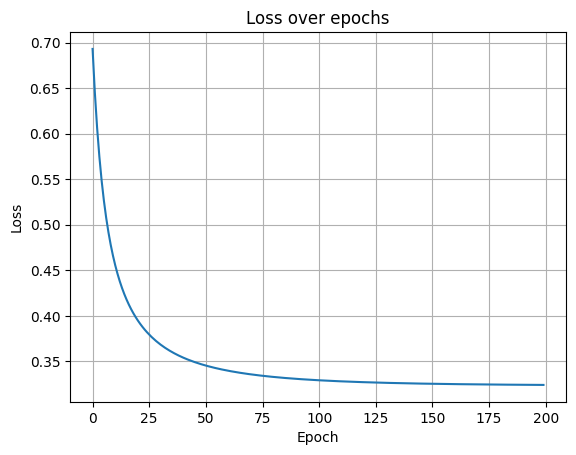

In [108]:
weights_trained, intercept_trained, losses = logistic_regression_gradient_descent(X_train, y_train, learning_rate=0.4, epochs=200)

print(weights_trained, intercept_trained)

plt.plot(losses)
plt.title("Loss over epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

&nbsp;

# Exercise 2: COMPAS (55 points)

Throughout this exercise, you'll be working with the data that ProPublica used in their own analysis of the COMPAS tool from Broward County public records of people who were scored between 2013 and 2014. See the methodology article for reference: [ProPublica](https://www.propublica.org/article/how-we-analyzed-the-compas-recidivism-algorithm). The data is available on Moodle under the filename `compas.csv`.

Here is a description of some of the important features in this dataset:
- `age`: age (in years) of the person;

- `sex`: binary "Female" or "Male";

- `race`: a factor encoding the race of the person;

- `juv_fel_count`: number of juvenile felonies;

- `juv_misd_count`: number of juvenile misdemeanors;

- `juv_other_count`: number of prior juvenile convictions that are not considered either felonies or misdemeanors;

- `priors_count`: number of prior crimes committed;

- `decile_score`: a continuous variable containing the decile COMPAS score;

- `c_charge_degree`: the degree of the current charge (misdemeanor or felony)

- `v_decile_score`: a continuous variable containing the violent crime decile COMPAS score;

- `two_year_recid`: if the person was rearrested within two years.

This data is not the data that COMPAS uses to make predictions. The model and data it uses are closed-source.

In order to follow ProPublica's analysis, we first remove any cases where the charge was not within 30 days of the score (ProPublica did this in order to match the COMPAS score with the correct criminal case).

&nbsp;

Run the following to load in and preprocess the data:

In [109]:
data = pd.read_csv('compas.csv')
data = data.query('days_b_screening_arrest <= 30 & days_b_screening_arrest >= -30')
data

data_original = data.copy()

data = data[["age", "c_charge_degree", "race", "age_cat", "sex", "priors_count", "days_b_screening_arrest",
                    "decile_score", "v_decile_score", "score_text", "v_score_text", "is_recid", "two_year_recid", "c_jail_in", "c_jail_out"]]

&nbsp;

Before you get started, let's make sure your data is loaded correctly. Output the number of rows in the data. There should be 6172 rows in the dataset.

In [110]:
data.shape[0]

6172

&nbsp;

## Q1 (2 pts)

Split the COMPAS dataframe `data` into two dataframes, one with all Black defendants and one with all white defendants.

In [111]:
black_data = data[data["race"] == "African-American"]
white_data = data[data["race"] == "Caucasian"]
black_data

,age,c_charge_degree,race,age_cat,sex,priors_count,days_b_screening_arrest,decile_score,v_decile_score,score_text,v_score_text,is_recid,two_year_recid,c_jail_in,c_jail_out
1,34,F,African-American,25 - 45,Male,0,-1.0,3,1,Low,Low,1,1,2013-01-26 03:45:27,2013-02-05 05:36:53
2,24,F,African-American,Less than 25,Male,4,-1.0,4,3,Low,Low,1,1,2013-04-13 04:58:34,2013-04-14 07:02:04
11,23,M,African-American,Less than 25,Male,3,0.0,6,4,Medium,Low,1,1,2013-10-03 04:07:35,2013-10-07 08:17:30
13,41,F,African-American,25 - 45,Male,0,-1.0,4,2,Low,Low,0,0,2013-10-08 11:53:09,2013-10-09 02:16:51
15,31,F,African-American,25 - 45,Male,7,22.0,3,2,Low,Low,1,1,2014-06-25 02:15:57,2014-06-28 05:02:21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7207,30,M,African-American,25 - 45,Male,0,-1.0,2,2,Low,Low,1,1,2014-05-09 10:01:33,2014-05-10 08:28:12
7208,20,F,African-American,Less than 25,Male,0,-1.0,9,9,High,High,0,0,2013-10-19 11:17:15,2013-10-20 08:13:06
7209,23,F,African-American,Less than 25,Male,0,-1.0,7,5,Medium,Medium,0,0,2013-11-22 05:18:27,2013-11-24 02:59:20
7210,23,F,African-American,Less than 25,Male,0,-1.0,3,5,Low,Medium,0,0,2014-01-31 07:13:54,2014-02-02 04:03:52


&nbsp;

## Q2 (5 pts)

Let’s recreate the plots of COMPAS score distributions that ProPublica began their investigation with. Plot two histograms displaying the overall crime decile scores of white and Black defendants. Then, plot two more histograms displaying the violent crime decile scores of white and Black defendants. Make sure to appropriately center your bins around each score (1 to 10).

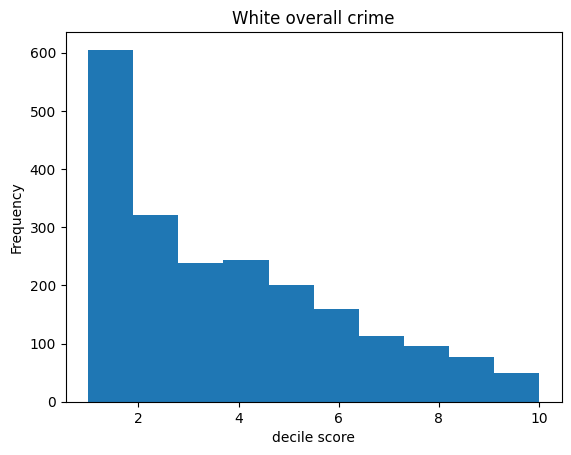

In [112]:
bins = np.arange(0.5, 11.5, 1)

white_data['decile_score'].plot.hist(title='White overall crime', xlabel='decile score')
plt.show()

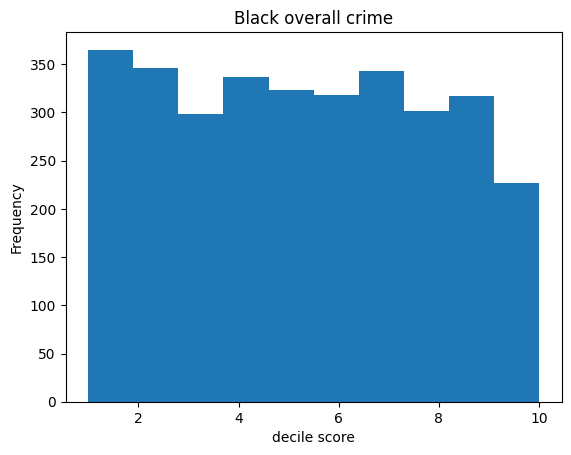

In [113]:
black_data['decile_score'].plot.hist(title='Black overall crime', xlabel='decile score')
plt.show()

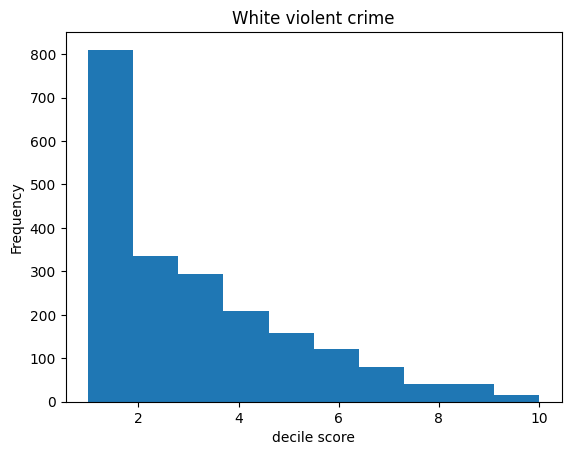

In [114]:
white_data['v_decile_score'].plot.hist(title='White violent crime', xlabel='decile score')
plt.show()

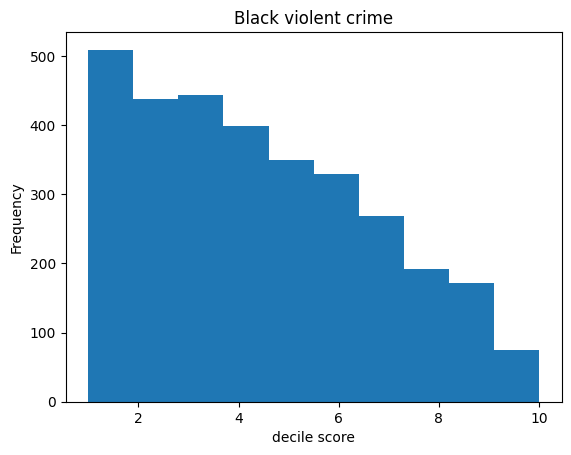

In [115]:
black_data['v_decile_score'].plot.hist(title='Black violent crime', xlabel='decile score')
plt.show()

## Q3 (5 pts)

Over the whole dataset (not your split dataframes from Q1 and Q2), use the overall crime decile scores (not violent crime) to make a new column labeled `pred` binary predictions for recidivism.

For all entries where the value of `score_text` is `Low`, the prediction `pred` should be 0. For all other entries, `pred` should be 1. (This is how ProPublica created its binary predictions.)

In [116]:
data['pred'] = data['score_text'].apply(lambda x: 0 if x == 'Low' else 1)
data

,age,c_charge_degree,race,age_cat,sex,priors_count,days_b_screening_arrest,decile_score,v_decile_score,score_text,v_score_text,is_recid,two_year_recid,c_jail_in,c_jail_out,pred
0,69,F,Other,Greater than 45,Male,0,-1.0,1,1,Low,Low,0,0,2013-08-13 06:03:42,2013-08-14 05:41:20,0
1,34,F,African-American,25 - 45,Male,0,-1.0,3,1,Low,Low,1,1,2013-01-26 03:45:27,2013-02-05 05:36:53,0
2,24,F,African-American,Less than 25,Male,4,-1.0,4,3,Low,Low,1,1,2013-04-13 04:58:34,2013-04-14 07:02:04,0
5,44,M,Other,25 - 45,Male,0,0.0,1,1,Low,Low,0,0,2013-11-30 04:50:18,2013-12-01 12:28:56,0
6,41,F,Caucasian,25 - 45,Male,14,-1.0,6,2,Medium,Low,1,1,2014-02-18 05:08:24,2014-02-24 12:18:30,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7209,23,F,African-American,Less than 25,Male,0,-1.0,7,5,Medium,Medium,0,0,2013-11-22 05:18:27,2013-11-24 02:59:20,1
7210,23,F,African-American,Less than 25,Male,0,-1.0,3,5,Low,Medium,0,0,2014-01-31 07:13:54,2014-02-02 04:03:52,0
7211,57,F,Other,Greater than 45,Male,0,-1.0,1,1,Low,Low,0,0,2014-01-13 05:48:01,2014-01-14 07:49:46,0
7212,33,M,African-American,25 - 45,Female,3,-1.0,2,2,Low,Low,0,0,2014-03-08 08:06:02,2014-03-09 12:18:04,0


&nbsp;

## Q4 (10 pts)

Using `pred`, calculate and plot the positive prediction rate, accuracy, false positive rate, and false negative rate by race. You should do this for all races in the data, not just Black and white defendants.

*Hint: You can use `MetricFrame` from the `fairlearn` package for this.*

                  Positive Prediction Rate  Accuracy  False Positive Rate  \
race                                                                        
African-American                  0.576063  0.649134             0.423382   
Asian                             0.225806  0.838710             0.086957   
Caucasian                         0.330956  0.671897             0.220141   
Hispanic                          0.277014  0.662083             0.193750   
Native American                   0.727273  0.727273             0.500000   
Other                             0.204082  0.679300             0.127854   

                  False Negative Rate  
race                                   
African-American             0.284768  
Asian                        0.375000  
Caucasian                    0.496350  
Hispanic                     0.582011  
Native American              0.000000  
Other                        0.661290  


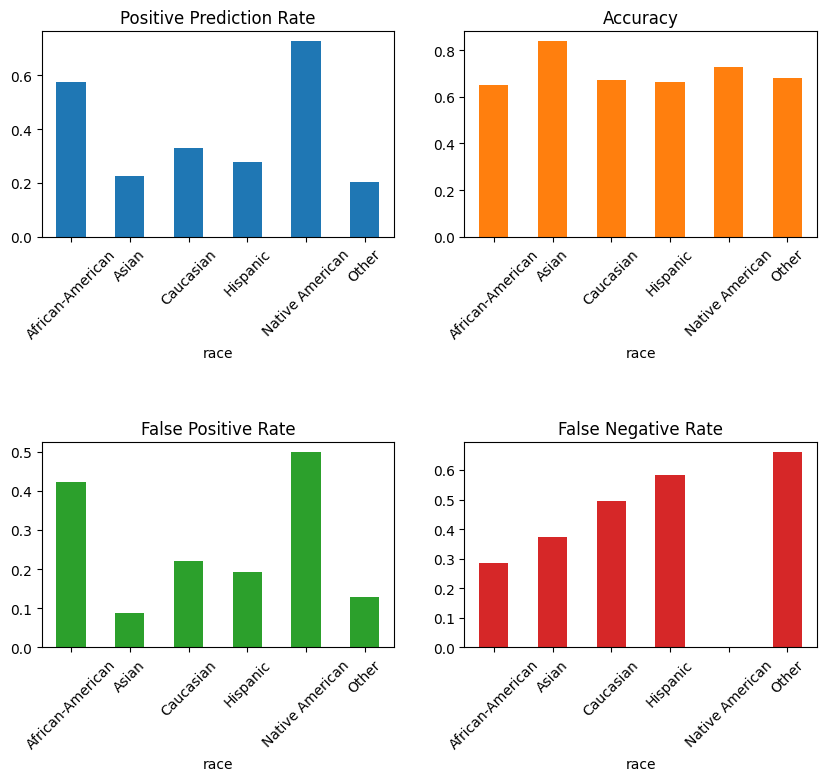

In [117]:
from fairlearn.metrics import MetricFrame, selection_rate, false_positive_rate, false_negative_rate
from sklearn.metrics import accuracy_score

metrics = {
    'Positive Prediction Rate': selection_rate,
    'Accuracy': accuracy_score,
    'False Positive Rate': false_positive_rate,
    'False Negative Rate': false_negative_rate
}

mf = MetricFrame(metrics=metrics, y_true=data['two_year_recid'], y_pred=data['pred'], sensitive_features=data['race'])

print(mf.by_group)
mf.by_group.plot.bar(subplots=True, layout=(2, 2), figsize=(10, 8), legend=False, sharex=False, rot=45)
plt.subplots_adjust(hspace=1)
plt.show()

&nbsp;

### Q4.1 (3 pts)
- Compare your metrics for Black and white defendants to ProPublica's. Do your FPR and FNR numbers align with ProPublica's?
  
- What is the importance of overprediction and underprediction in regard to ProPublica’s analysis? How might these observations have real impacts on the defendants who receive scores?

  
- How do ProPublica’s conclusions reflect the racial disparities in our current criminal justice system? Why?

**Answer:**

- My FPR and FNR numbers are overall very similar to ProPublica's:
    - Black FPR: 42.33 (Me) vs. 44.85 (ProPublica)
    - Black FNR: 28.47 vs. 27.99
    - White FPR: 22.01 vs. 23.45
    - White FNR: 49.64 vs. 47.72

- Chronic mistakes in making predicitons results in the perpetualisation of systemic racism. Black defendents having an extremely high FPR means they are disproportionately labeled as likely to commit more crimes, placing them under further scrutiny to reoffend and creating a confirmation bias if they do. On the other hand, white defendents having a super high FNR indicates that the system views them as intrinsically lower risk and enables more crime. With this contrast, the COMPAS system clearly favors white defendents.

- ProPublic'as resarch on COMPAS reflected a key element of systemic injustice, as I just outlined above: Bias against one group, and bias in favor of another group. Together this widens the inequality between these groups. Black defendants who did not reoffend were nearly twice as likely as white defendants to be wrongly labeled high risk (45% vs. 23%), while white defendants who did reoffend were nearly twice as likely to be wrongly labeled low risk (48% vs. 28%). Even after controlling for prior crimes, age, gender, and future recidivism, Black defendants were 45% more likely to receive higher risk scores.

&nbsp;

## Q4.2 (2 pts)
- In terms of accuracy and positive prediction rates, does COMPAS exhibit bias between Black and white defendants? Explain.

  
- On which race or races does COMPAS perform the worst?

  
- (Optional) What else strikes you about these metrics by race?



**Answer:**

- Yes, COMPAS exhibits extreme bias between Black and white defendents. This is evidenced in the fact that even after controlling for age, gender, prior arrests/convictions, and future recedivism, Black defendents were 45% more likely to receive a higher score.

- According to the sklearn.metrics accuracy score, there is no clear 'loser' in performance among all the specified races. However, it is very apparent that Black defendents and Native American defendents suffered the worst when it came to receiving false postive scores.


&nbsp;

## Make your own models

In this last set of questions, you're going to use the data we have to train a few models and compare them with COMPAS.

## Q5 (10 pts)

Train a classifier to predict recidivism within two years using logistic regression. For features, use the defendant's age, sex, count of juvenile felony, misdemeanor, and other convictions, their count of prior convictions, and the degree of the charge. For the ground truth predictive outcome, use recidivism within two years. You should split the data into train and test before training.

*Hint:* For Q5-Q7, we won't evaluate biases and fairness --- we'll just measure model accuracy over the whole test set. We'll look at fairness and biases in Q8.

In [118]:
data_copy = data_original.copy()

data_copy['sex'] = (data_copy['sex'] == 'Male').astype(int)
data_copy['c_charge_degree'] = (data_copy['c_charge_degree'] == 'F').astype(int)
data_copy['pred'] = data['pred']

features = ['age', 'sex', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'priors_count', 'c_charge_degree']

train, test = train_test_split(data_copy, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(train[features], train['two_year_recid'])

LogisticRegression(max_iter=1000)

&nbsp;

## Q6 (3 pts)

Report the overall accuracy of the binary predictions of your model over the test set.

In [119]:
test_pred = model.predict(test[features])
print((test_pred == test['two_year_recid']).mean() * 100, "%")

65.9919028340081 %


&nbsp;

## Q7 (3 pts)

Now, let's compare the binary predictions of your model versus those of COMPAS on the test set.

Report the percent of observations where the binary prediction that your model output are equal to the binary predictions `pred` from COMPAS (that you calculated in Q4).

In [120]:
print((test_pred == test['pred']).mean() * 100, "%")

72.5506072874494 %


&nbsp;

## Q8 (10 pts)

Using the `fairlearn` package, train a classifier with the same features and predictive outcome as as above, but with equal false positive rates between Black and white defendants. Set the keyword argument `difference_bound=0.01`.

Report the overall accuracy of your fairness-constrained model. Then, report the positive prediction rate, accuracy, FPR, and FNR between Black and white defendants.

In [121]:
model = ExponentiatedGradient(LogisticRegression(max_iter=1000), constraints=FalsePositiveRateParity(difference_bound=0.01))

model.fit(train[features], train['two_year_recid'], sensitive_features=train['race'])

pred = model.predict(test[features])

# overall accuracy
print((pred == test['two_year_recid']).mean())

metrics = {
    'Positive Prediction Rate': selection_rate,
    'Accuracy': accuracy_score,
    'False Positive Rate': false_positive_rate,
    'False Negative Rate': false_negative_rate
}

fair = MetricFrame(metrics=metrics, y_true=test['two_year_recid'], y_pred=pred, sensitive_features=test['race'])

print(fair.by_group.loc[['African-American', 'Caucasian']])

0.582995951417004
                  Positive Prediction Rate  Accuracy  False Positive Rate  \
race                                                                        
African-American                  0.335505  0.612378             0.220395   
Caucasian                         0.301762  0.535242             0.303704   

                  False Negative Rate  
race                                   
African-American             0.551613  
Caucasian                    0.701087  


&nbsp;

### Q9 (2 pts)

How does the overall accuracy rate of your fairness-constrained classifier compare to:

1.   the accuracy of the unconstrained classifier you trained; and
2.   the accuracy of COMPAS?
  
Why do you think you see these results?

**Answer:**

&nbsp;

&nbsp;

## Turning in your assignment

Before you export and turn in your code, you must restart your runtime and run all of your code. Make sure the name of your file is something descriptive (not just `"Copy of Assignment X"`). Then, export your code as an .ipynb file. Turn in just your .ipynb file on Gradescope (or Moodle).

**The outputs of your code must be displayed when you export your code in order to receive full credit.**